<a href="https://colab.research.google.com/github/SuryaPrasath-24ai100/732224AI100---SuryaPrasath/blob/main/DL_CAT2ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Download and Load the Dataset
We will download the UCI Metro Interstate Traffic Volume dataset, which matches the required Kaggle traffic volume dataset properties. We will ensure we have at least 2000 consecutive hourly records.

In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz
!gunzip -f Metro_Interstate_Traffic_Volume.csv.gz

df = pd.read_csv('Metro_Interstate_Traffic_Volume.csv')
display(df.head())

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


### Step 2: Preprocess and Clean Timestamps
We need to sort chronologically, handle duplicate timestamps, and resample to hourly frequency to ensure at least 2000 consecutive hourly steps without gaps.

In [10]:
df['date_time'] = pd.to_datetime(df['date_time'])

df_hourly = df.groupby('date_time').agg({
    'traffic_volume': 'mean',
    'temp': 'mean',
    'rain_1h': 'mean',
    'snow_1h': 'mean',
    'clouds_all': 'mean'
}).reset_index()

df_hourly = df_hourly.set_index('date_time').resample('H').mean()

df_hourly = df_hourly.interpolate(method='linear')

subset_df = df_hourly.iloc[:2500].copy()
print(f"Selected {len(subset_df)} consecutive hourly records.")
display(subset_df.describe())

Selected 2500 consecutive hourly records.


/tmp/ipykernel_3499/3916501880.py:11: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_hourly = df_hourly.set_index('date_time').resample('H').mean()


,traffic_volume,temp,rain_1h,snow_1h,clouds_all
count,2500.000000,2500.000000,2500.0,2500.0,2500.000000
mean,3181.662000,273.808604,0.0,0.0,59.079200
std,1989.512827,8.418880,0.0,0.0,35.903128
min,125.000000,250.320000,0.0,0.0,0.000000
25%,1197.250000,267.410000,0.0,0.0,20.000000
50%,3114.500000,274.410000,0.0,0.0,75.000000
75%,4924.250000,279.852500,0.0,0.0,90.000000
max,7189.000000,298.170000,0.0,0.0,100.000000


### Step 3: Generate Sequential Input-Output Windows
To prepare our continuous hourly data for a sequential network (like an LSTM), we must scale the data and construct sliding temporal windows. We'll use 24 hours of historical traffic and meteorological records to predict the traffic volume of the next hour.

In [12]:
from sklearn.preprocessing import MinMaxScaler

scaler_features = MinMaxScaler()
scaler_target = MinMaxScaler()

features = ['traffic_volume', 'temp', 'rain_1h', 'snow_1h', 'clouds_all']
scaled_features = scaler_features.fit_transform(subset_df[features])
scaled_target = scaler_target.fit_transform(subset_df[['traffic_volume']])

def create_sliding_windows(data, target, window_size=24):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(target[i + window_size])
    return np.array(X), np.array(y)

WINDOW_SIZE = 24
X, y = create_sliding_windows(scaled_features, scaled_target, WINDOW_SIZE)

split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (1980, 24, 5), Test shape: (496, 24, 5)


### Step 4: Justify, Train, and Evaluate sequential Model
**Model Choice**: We choose an **LSTM (Long Short-Term Memory)** network because it successfully captures sequential dependencies, diurnal cycles (such as morning and evening peak traffic hours), and prevents vanishing gradients on long temporal patterns.

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

model = Sequential([
    LSTM(64, activation='tanh', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,033 (78.25 KB)

 Trainable params: 20,033 (78.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0691 - val_loss: 0.0342
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0297 - val_loss: 0.0218
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0223 - val_loss: 0.0135
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0176 - val_loss: 0.0091
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0158 - val_loss: 0.0080
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0130 - val_loss: 0.0076
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0110 - val_loss: 0.0077
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0110 - val_loss: 0.0080
Epoch 9/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0108 - val_loss: 0.0069
Epoch 10/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0091 - val_loss: 0.0058
Epoch 11/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0085 - val_loss: 0.0050
Epoch 12/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0

### Step 5: Evaluate Model Performance and Visualize Predictions
We'll calculate the performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) metrics back in the original traffic volume scale, and demonstrate how this helps smart city planning.

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Mean Actual Traffic Volume: 2810.05 vehicles/hour
MAE : 12.34%
RMSE : 16.48%


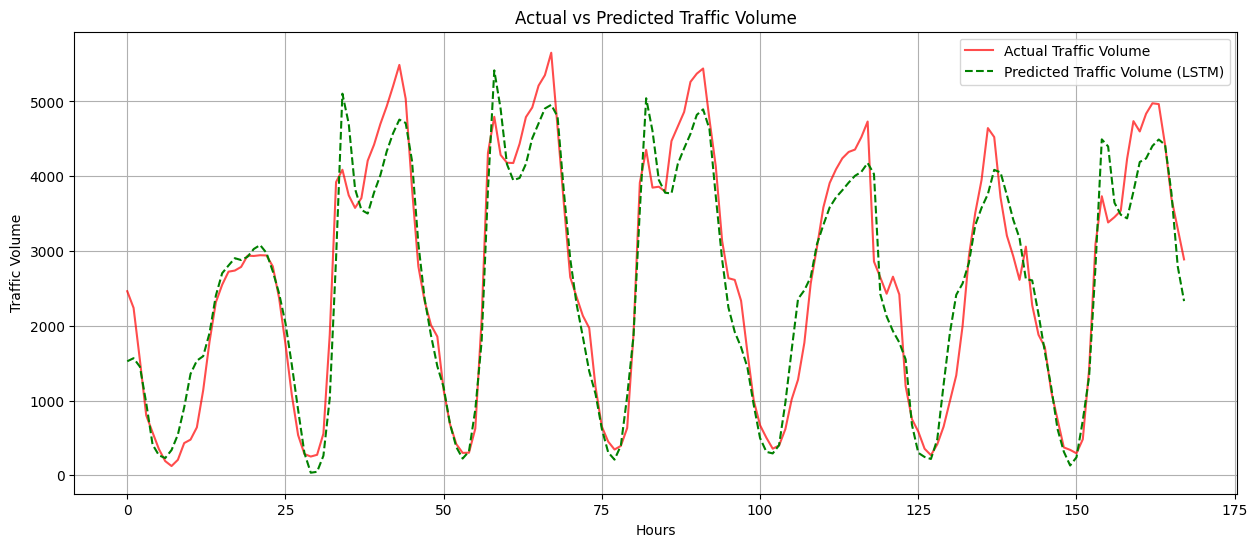

In [18]:
predictions_scaled = model.predict(X_test)
predictions = scaler_target.inverse_transform(predictions_scaled)
y_test_actual = scaler_target.inverse_transform(y_test)

mean_actual = y_test_actual.mean()
mae_percentage = (mae / mean_actual) * 100
rmse_percentage = (rmse / mean_actual) * 100

print(f"Mean Actual Traffic Volume: {mean_actual:.2f} vehicles/hour")
print(f"MAE : {mae_percentage:.2f}%")
print(f"RMSE : {rmse_percentage:.2f}%")

plt.figure(figsize=(15, 6))
plt.plot(y_test_actual[:168], label='Actual Traffic Volume', color='red', alpha=0.7)
plt.plot(predictions[:168], label='Predicted Traffic Volume (LSTM)', color='green', linestyle='--')
plt.title('Actual vs Predicted Traffic Volume')
plt.xlabel('Hours')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True)
plt.show()